# BCG X | PowerCo Customer Churn — Modeling & Evaluation

**Task:** Train a Random Forest classifier using `data_for_predictions.csv`, evaluate its predictions, and explain whether performance is satisfactory.

## Business problem
PowerCo wants to identify customers likely to churn. The target is `churn` (`1` = churned, `0` = did not churn).

## Approach
1. Load and inspect the final feature-engineered dataset.
2. Separate the target from input features.
3. Split the data into training and test sets using stratification.
4. Train a Random Forest classifier.
5. Evaluate with a confusion matrix, precision, recall, F1-score, ROC-AUC, and accuracy.
6. Explain the results and limitations.

**Important:** The target is imbalanced, so accuracy alone is not enough. Recall and precision for churners are especially important. The test split estimates performance on held-out data; it does not prove future performance or causation.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)

pd.set_option("display.max_columns", 70)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid")

## 2. Load and inspect the final dataset

Keep `data_for_predictions.csv` in the same folder as this notebook.

In [2]:
DATA_FILE = Path("data_for_predictions.csv")
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_FILE.resolve()}. Put data_for_predictions.csv beside this notebook."
    )

df = pd.read_csv(DATA_FILE)

# Remove the saved DataFrame index if it is present; it is not a real feature.
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("\nFirst five rows:")
display(df.head())

print("\nData types:")
display(df.dtypes.astype(str).to_frame("dtype"))

print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).head(15).to_frame("missing_count"))

print("\nChurn distribution:")
display(df["churn"].value_counts().rename("customers").to_frame())
display((df["churn"].value_counts(normalize=True) * 100).round(2).rename("percentage").to_frame())

Dataset shape: 14,606 rows × 63 columns

First five rows:


,id,cons_12m,cons_gas_12m,cons_last_month,forecast_cons_12m,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,pow_max,var_year_price_off_peak_var,var_year_price_peak_var,var_year_price_mid_peak_var,var_year_price_off_peak_fix,var_year_price_peak_fix,var_year_price_mid_peak_fix,var_year_price_off_peak,var_year_price_peak,var_year_price_mid_peak,var_6m_price_off_peak_var,var_6m_price_peak_var,var_6m_price_mid_peak_var,var_6m_price_off_peak_fix,var_6m_price_peak_fix,var_6m_price_mid_peak_fix,var_6m_price_off_peak,var_6m_price_peak,var_6m_price_mid_peak,churn,offpeak_diff_dec_january_energy,offpeak_diff_dec_january_power,off_peak_peak_var_mean_diff,peak_mid_peak_var_mean_diff,off_peak_mid_peak_var_mean_diff,off_peak_peak_fix_mean_diff,peak_mid_peak_fix_mean_diff,off_peak_mid_peak_fix_mean_diff,off_peak_peak_var_max_monthly_diff,peak_mid_peak_var_max_monthly_diff,off_peak_mid_peak_var_max_monthly_diff,off_peak_peak_fix_max_monthly_diff,peak_mid_peak_fix_max_monthly_diff,off_peak_mid_peak_fix_max_monthly_diff,tenure,months_activ,months_to_end,months_modif_prod,months_renewal,channel_MISSING,channel_ewpakwlliwisiwduibdlfmalxowmwpci,channel_foosdfpfkusacimwkcsosbicdxkicaua,channel_lmkebamcaaclubfxadlmueccxoimlema,channel_usilxuppasemubllopkaafesmlibmsdf,origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws,origin_up_ldkssxwpmemidmecebumciepifcamkci,origin_up_lxidpiddsbxsbosboudacockeimpuepw
0,24011ae4ebbe3035111d65fa7c15bc57,0.0000,4.7399,0.0000,0.0000,0.0000,0.4440,0.1145,0.0981,40.6067,1,0.0000,25.4400,25.4400,2,678.9900,43.6480,0.0001,0.0000,0.0004,1.1028,49.5507,22.0225,1.1028,49.5507,22.0230,0.0001,0.0000,0.0009,2.0863,99.5305,44.2358,2.0864,99.5306,44.2367,1,0.0201,3.7010,0.0240,0.0342,0.0583,18.5903,7.4507,26.0409,0.0605,0.0855,0.1460,44.2669,8.1458,44.2669,3,30,5,2,6,0,0,1,0,0,0,0,1
1,d29c2c54acc38ff3c0614d0a653813dd,3.6685,0.0000,0.0000,2.2809,0.0000,1.2373,0.1457,0.0000,44.3114,0,0.0000,16.3800,16.3800,1,18.8900,13.8000,0.0000,0.0006,0.0000,0.0065,0.0000,0.0000,0.0065,0.0006,0.0000,0.0000,0.0012,0.0000,0.0095,0.0000,0.0000,0.0095,0.0012,0.0000,0,-0.0038,0.1778,0.1425,0.0071,0.1496,44.3114,0.0000,44.3114,0.1514,0.0855,0.1514,44.4447,0.0000,44.4447,7,76,7,76,4,1,0,0,0,0,1,0,0
2,764c75f661154dac3a6c254cd082ea7d,2.7364,0.0000,0.0000,1.6898,0.0000,1.5990,0.1658,0.0879,44.3114,0,0.0000,28.6000,28.6000,1,6.6000,13.8560,0.0000,0.0000,0.0000,0.0077,0.0000,0.0000,0.0077,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0,-0.0047,0.1778,0.0821,0.0884,0.1705,44.3855,0.0000,44.3855,0.0846,0.0892,0.1725,44.4447,0.0000,44.4447,6,68,3,68,8,0,0,1,0,0,1,0,0
3,bba03439a292a1e166f80264c16191cb,3.2000,0.0000,0.0000,2.3821,0.0000,1.3187,0.1467,0.0000,44.3114,0,0.0000,30.2200,30.2200,1,25.4600,13.2000,0.0000,0.0000,0.0000,0.0065,0.0000,0.0000,0.0065,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0,-0.0045,0.1778,0.1512,0.0000,0.1512,44.4003,0.0000,44.4003,0.1531,0.0000,0.1531,44.4447,0.0000,44.4447,6,69,2,69,9,0,0,0,1,0,1,0,0
4,149d57cf92fc41cf94415803a877cb4b,3.6460,0.0000,2.7218,2.6501,0.0000,2.1230,0.1169,0.1000,40.6067,0,1.7269,44.9100,44.9100,1,47.9800,19.8000,0.0000,0.0000,0.0000,0.0054,0.0020,0.0009,0.0054,0.0020,0.0009,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0,-0.0062,0.1629,0.0205,0.0308,0.0513,16.2753,8.1376,24.4129,0.0222,0.0337,0.0559,16.2916,8.1458,24.4373,6,71,2,71,9,1,0,0,0,0,1,0,0



Data types:


,dtype
id,object
cons_12m,float64
cons_gas_12m,float64
cons_last_month,float64
forecast_cons_12m,float64
...,...
channel_lmkebamcaaclubfxadlmueccxoimlema,int64
channel_usilxuppasemubllopkaafesmlibmsdf,int64
origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws,int64
origin_up_ldkssxwpmemidmecebumciepifcamkci,int64



Missing values:


,missing_count
id,0
off_peak_peak_fix_max_monthly_diff,0
var_6m_price_mid_peak,0
churn,0
offpeak_diff_dec_january_energy,0
offpeak_diff_dec_january_power,0
off_peak_peak_var_mean_diff,0
peak_mid_peak_var_mean_diff,0
off_peak_mid_peak_var_mean_diff,0
off_peak_peak_fix_mean_diff,0



Churn distribution:


,customers
churn,
0,13187
1,1419


,percentage
churn,
0,90.2800
1,9.7200


## 3. Prepare features and target

`churn` is the target variable. `id` is an identifier rather than a meaningful predictive input, so we exclude it. The saved row index is excluded above. The supplied final dataset is expected to contain already-prepared numeric features.

In [3]:
if "churn" not in df.columns:
    raise KeyError("The target column 'churn' was not found.")

y = df["churn"].astype(int)
drop_cols = ["churn"]
if "id" in df.columns:
    drop_cols.append("id")

X = df.drop(columns=drop_cols).copy()

# Verify the model inputs are numeric and finite.
non_numeric = X.select_dtypes(exclude=[np.number, "bool"]).columns.tolist()
if non_numeric:
    raise ValueError(
        "The following feature columns are not numeric and need encoding first: "
        + ", ".join(non_numeric)
    )

X = X.replace([np.inf, -np.inf], np.nan)
if X.isna().any().any():
    missing_cols = X.columns[X.isna().any()].tolist()
    raise ValueError(
        "Missing/non-finite feature values found in: "
        + ", ".join(missing_cols)
        + ". Inspect and handle these before model training."
    )

print("Feature matrix:", X.shape)
print("Target:", y.shape)
print("Features used:", X.shape[1])
print("Target classes:", sorted(y.unique()))

Feature matrix: (14606, 61)
Target: (14606,)
Features used: 61
Target classes: [np.int64(0), np.int64(1)]


## 4. Split into training and test data

We use a 75% training / 25% test split. `stratify=y` preserves approximately the same churn proportion in both sets, which matters because churners are the minority class.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("\nChurn rate — full dataset:", round(y.mean() * 100, 2), "%")
print("Churn rate — training set:", round(y_train.mean() * 100, 2), "%")
print("Churn rate — test set:", round(y_test.mean() * 100, 2), "%")

Training features: (10954, 61)
Test features: (3652, 61)

Churn rate — full dataset: 9.72 %
Churn rate — training set: 9.71 %
Churn rate — test set: 9.72 %


## 5. Train the Random Forest classifier

`class_weight='balanced'` gives additional weight to the less common churn class. We set `random_state` for reproducibility and use `n_jobs=-1` to use available CPU cores.

In [5]:
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
print("Random Forest training complete.")

Random Forest training complete.


## 6. Generate predictions

We calculate both predicted classes and churn probabilities. The default classification threshold is 0.5; later business use may require a different threshold depending on retention costs and priorities.

In [6]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("First 10 actual labels:    ", y_test.iloc[:10].to_list())
print("First 10 predicted labels: ", y_pred[:10].tolist())

First 10 actual labels:     [1, 0, 0, 0, 0, 0, 0, 0, 0, 0]
First 10 predicted labels:  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## 7. Evaluate model performance

- **Accuracy:** overall fraction classified correctly; can be misleading with imbalanced targets.
- **Precision (churn = 1):** among customers predicted to churn, how many actually churned.
- **Recall (churn = 1):** among all actual churners, how many the model identified.
- **F1-score:** balance between precision and recall.
- **ROC-AUC:** ability to rank churners above non-churners across thresholds.

For retention, recall helps estimate how many at-risk customers are found, while precision helps estimate how much outreach may be directed to customers who would not churn.

In [7]:
metrics_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (churn=1)", "Recall (churn=1)", "F1-score (churn=1)", "ROC-AUC"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_proba)
    ]
})
display(metrics_summary.style.format({"Score": "{:.3f}"}))

print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Did not churn (0)", "Churned (1)"],
    zero_division=0
))

,Metric,Score
0,Accuracy,0.909
1,Precision (churn=1),0.745
2,Recall (churn=1),0.099
3,F1-score (churn=1),0.174
4,ROC-AUC,0.699



Classification report:
                   precision    recall  f1-score   support

Did not churn (0)       0.91      1.00      0.95      3297
      Churned (1)       0.74      0.10      0.17       355

         accuracy                           0.91      3652
        macro avg       0.83      0.55      0.56      3652
     weighted avg       0.90      0.91      0.88      3652



## 8. Confusion matrix and ROC curve

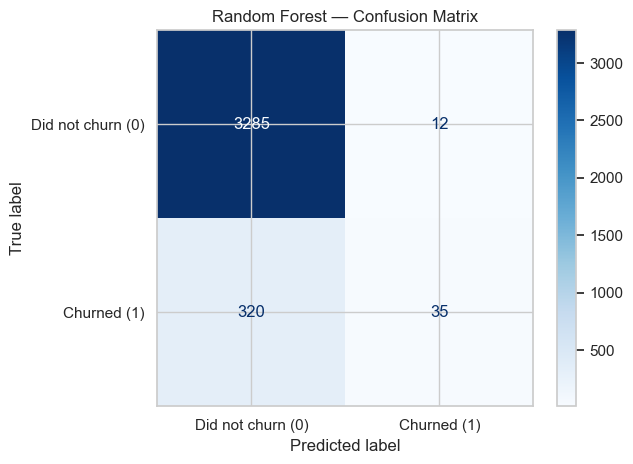

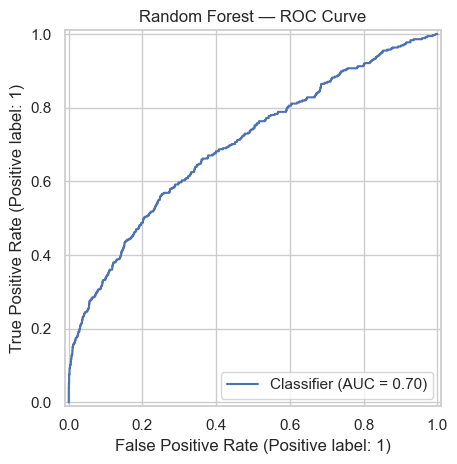

In [8]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did not churn (0)", "Churned (1)"]
)
disp.plot(values_format="d", cmap="Blues")
plt.title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("Random Forest — ROC Curve")
plt.tight_layout()
plt.show()

## 9. Feature importance

Random Forest impurity-based feature importance can provide a first look at which features the model uses. It is not causal evidence, and importance can be biased toward certain feature types or spread across correlated features.

,importance
margin_net_pow_ele,0.0526
margin_gross_pow_ele,0.0520
cons_12m,0.0518
forecast_meter_rent_12m,0.0507
net_margin,0.0441
forecast_cons_12m,0.0421
cons_last_month,0.0374
months_activ,0.0330
pow_max,0.0325
var_year_price_off_peak_var,0.0321


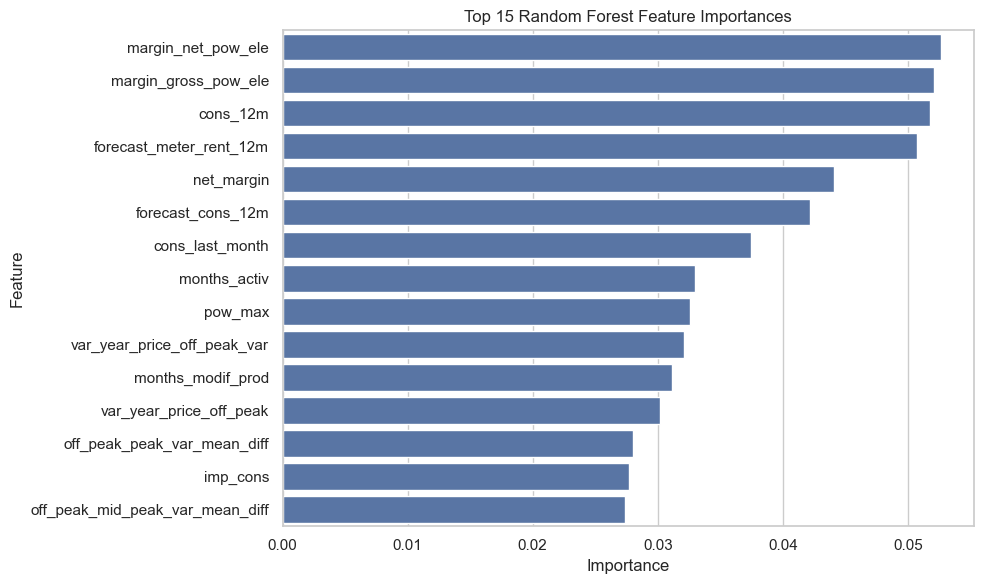

In [9]:
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
display(importance.head(15).to_frame("importance"))

plt.figure(figsize=(10, 6))
sns.barplot(x=importance.head(15).values, y=importance.head(15).index)
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 10. Is the model performance satisfactory?

Use the actual metrics above to write your assessment. Do not call the model satisfactory based on accuracy alone.

A strong assessment should answer:
- How many churners were found (recall for class 1)?
- How many customers flagged as churn risks were truly churners (precision for class 1)?
- Does the F1-score offer a useful balance for the business?
- Is ROC-AUC meaningfully above 0.5 (random ranking)?
- What are the costs of missing a churner versus contacting a customer who would have stayed?

**Suggested interpretation template:**

> I evaluated the Random Forest using accuracy, precision, recall, F1-score, ROC-AUC and the confusion matrix. Accuracy summarizes overall correctness, but churn is the minority class, so I focused especially on churn-class recall and precision. The model's suitability depends on whether it identifies enough churners without generating too many false alarms. The test-set results are an initial benchmark; I would validate them with cross-validation, compare against a simple baseline, and tune the decision threshold based on the cost of retention actions before deployment.

## 11. Limitations and next steps

1. This is a single train/test split; cross-validation would provide a more stable estimate.
2. `class_weight='balanced'` changes the penalty for mistakes but does not guarantee better performance on every metric.
3. Feature importance does not prove that a feature causes churn.
4. Check feature timing carefully to prevent leakage: every input must be available before the churn prediction period.
5. Tune the classification threshold according to retention campaign costs and capacity.
6. Compare with a baseline and consider precision-recall curves because churn is relatively uncommon.